## 1. Importarea bibliotecilor și a setului de date Penguins

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
dataset = sns.load_dataset("penguins")
print("Dimensiunea setului de date:", dataset.shape)
display(dataset.head())

Dimensiunea setului de date: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## 2. Analiza exploratorie a datelor (EDA)

### 2.1. Afișarea coloanelor

In [3]:
print("Lista de coloane:", dataset.columns.to_list())

Lista de coloane: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


### 2.2. Verificarea valorilor lipsă

In [4]:
print("Valori lipsă:")
print(dataset.isna().sum())

Valori lipsă:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


### 2.3. Verificarea tipurilor de date și descrierea statistică

In [5]:
print("Tipuri de date:")
print(dataset.dtypes)

display(dataset.describe(include="all"))

Tipuri de date:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
count,344,344,342.000000,342.000000,342.000000,342.000000,333
unique,3,3,NaN,NaN,NaN,NaN,2
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,Male
freq,152,168,NaN,NaN,NaN,NaN,168
mean,NaN,NaN,43.921930,17.151170,200.915205,4201.754386,NaN
std,NaN,NaN,5.459584,1.974793,14.061714,801.954536,NaN
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN


### 2.4. Distribuția variabilei țintă

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


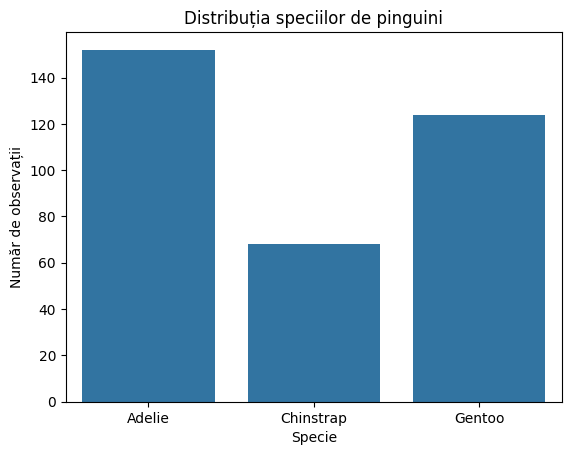

In [6]:
print(dataset["species"].value_counts())

sns.countplot(data=dataset, x="species")
plt.title("Distribuția speciilor de pinguini")
plt.xlabel("Specie")
plt.ylabel("Număr de observații")
plt.show()

## 3. Preprocesarea datelor

### 3.1. Separarea caracteristicilor numerice și categoriale

In [7]:
numeric_features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

categorial_features = ["island", "sex"]

### 3.2. Înlocuirea valorilor lipsă pentru atributele numerice

In [8]:
numericalImputer = SimpleImputer(strategy="mean")
dataset_num = numericalImputer.fit_transform(dataset[numeric_features])

### 3.3. Aplicarea transformărilor numerice

In [9]:
dataset[numeric_features] = dataset_num
display(dataset.describe())

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,344.000000,344.000000,344.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.443643,1.969027,14.020657,799.613058
min,32.100000,13.100000,172.000000,2700.000000
25%,39.275000,15.600000,190.000000,3550.000000
50%,44.250000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


### 3.4. Înlocuirea valorilor lipsă pentru atributele categoriale

In [10]:
categoricalImputer = SimpleImputer(strategy="most_frequent")
dataset_cat = categoricalImputer.fit_transform(dataset[categorial_features])
dataset[categorial_features] = dataset_cat

print(dataset.isna().sum())

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


### 3.5. Codificarea atributelor categoriale – One-Hot Encoding

In [11]:
dataset = pd.get_dummies(dataset, columns=categorial_features)
display(dataset.head())

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Biscoe,island_Dream,island_Torgersen,sex_Female,sex_Male
0,Adelie,39.10000,18.70000,181.000000,3750.000000,False,False,True,False,True
1,Adelie,39.50000,17.40000,186.000000,3800.000000,False,False,True,True,False
2,Adelie,40.30000,18.00000,195.000000,3250.000000,False,False,True,True,False
3,Adelie,43.92193,17.15117,200.915205,4201.754386,False,False,True,False,True
4,Adelie,36.70000,19.30000,193.000000,3450.000000,False,False,True,True,False


## 4. Clasificare binară

În acest model sunt selectate numai două dintre cele trei specii, *Adelie* și *Gentoo*. Specia *Chinstrap* nu participă la această etapă.

### 4.1. Selectarea claselor

In [12]:
dataset_binary = dataset[
    dataset["species"].isin(["Adelie", "Gentoo"])
].copy()

print("Dimensiunea setului binar:", dataset_binary.shape)
print(dataset_binary["species"].value_counts())

Dimensiunea setului binar: (276, 10)
species
Adelie    152
Gentoo    124
Name: count, dtype: int64


### 4.2. Definirea matricii de caracteristici și a vectorului țintă

In [13]:
X = dataset_binary.drop("species", axis=1)
y = dataset_binary["species"].map({"Adelie": 0, "Gentoo": 1})

print("Dimensiunea X:", X.shape)
print("Dimensiunea y:", y.shape)

Dimensiunea X: (276, 9)
Dimensiunea y: (276,)


### 4.3. Împărțirea setului de date

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (207, 9)
X_test: (69, 9)


### 4.4. Definirea și antrenarea modelului Decision Tree

In [15]:
model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

### 4.5. Predicții și evaluarea modelului

In [16]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Acuratețe: ", accuracy)

precision = precision_score(y_test, y_pred, zero_division=0)
print("Precizie: ", precision)

recall = recall_score(y_test, y_pred, zero_division=0)
print("Recall: ", recall)

f1 = f1_score(y_test, y_pred, zero_division=0)
print("Scor F1: ", f1)

Acuratețe:  0.9565217391304348
Precizie:  0.9117647058823529
Recall:  1.0
Scor F1:  0.9538461538461539


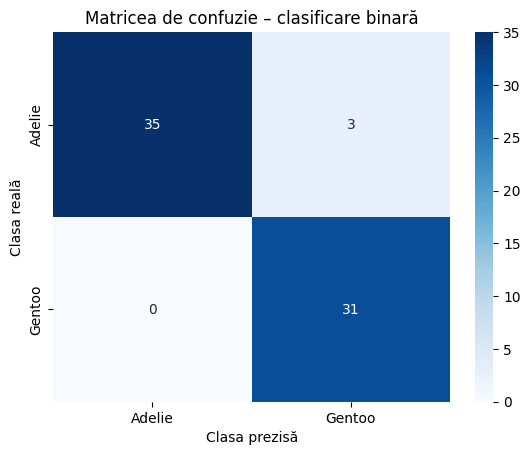

In [17]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Adelie", "Gentoo"],
    yticklabels=["Adelie", "Gentoo"]
)
plt.xlabel("Clasa prezisă")
plt.ylabel("Clasa reală")
plt.title("Matricea de confuzie – clasificare binară")
plt.show()

## 5. Clasificare multiclasă

În această etapă sunt utilizate toate cele trei clase: *Adelie*, *Chinstrap* și *Gentoo*.

### 5.1. Definirea caracteristicilor și codificarea claselor

In [18]:
X = dataset.drop("species", axis=1)
encoder = LabelEncoder()
y = encoder.fit_transform(dataset["species"])

print("Clase:", encoder.classes_)
print("Dimensiunea X:", X.shape)
print("Dimensiunea y:", y.shape)

Clase: ['Adelie' 'Chinstrap' 'Gentoo']
Dimensiunea X: (344, 9)
Dimensiunea y: (344,)


### 5.2. Împărțirea datelor

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (258, 9)
X_test: (86, 9)


### 5.3. Antrenarea modelului pentru clasificare multiclasă

In [20]:
model_multi = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

model_multi.fit(X_train, y_train)
y_pred = model_multi.predict(X_test)

### 5.4. Evaluarea modelului multiclasă

In [21]:
accuracy = accuracy_score(y_test, y_pred)
print("Acuratețe: ", accuracy)

precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
print("Precizie: ", precision)

recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
print("Recall: ", recall)

f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
print("Scor F1: ", f1)

Acuratețe:  0.9883720930232558
Precizie:  0.9895833333333334
Recall:  0.9912280701754387
Scor F1:  0.9902645502645503


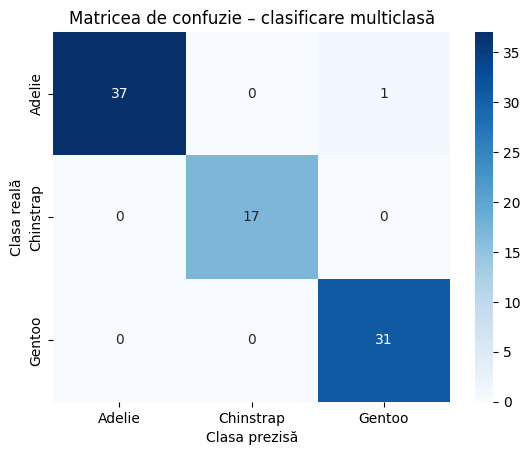

In [22]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)
plt.xlabel("Clasa prezisă")
plt.ylabel("Clasa reală")
plt.title("Matricea de confuzie – clasificare multiclasă")
plt.show()

## 6. Înțelegerea și vizualizarea arborelui decizional

### 6.3. Reprezentarea grafică a arborelui

Arborele antrenat poate fi reprezentat cu funcția `plot_tree()`. Pentru exemplul multiclasă, se reprezintă primele niveluri ale arborelui pentru a păstra diagrama lizibilă. Limitarea afectează numai figura, nu și modelul deja antrenat.

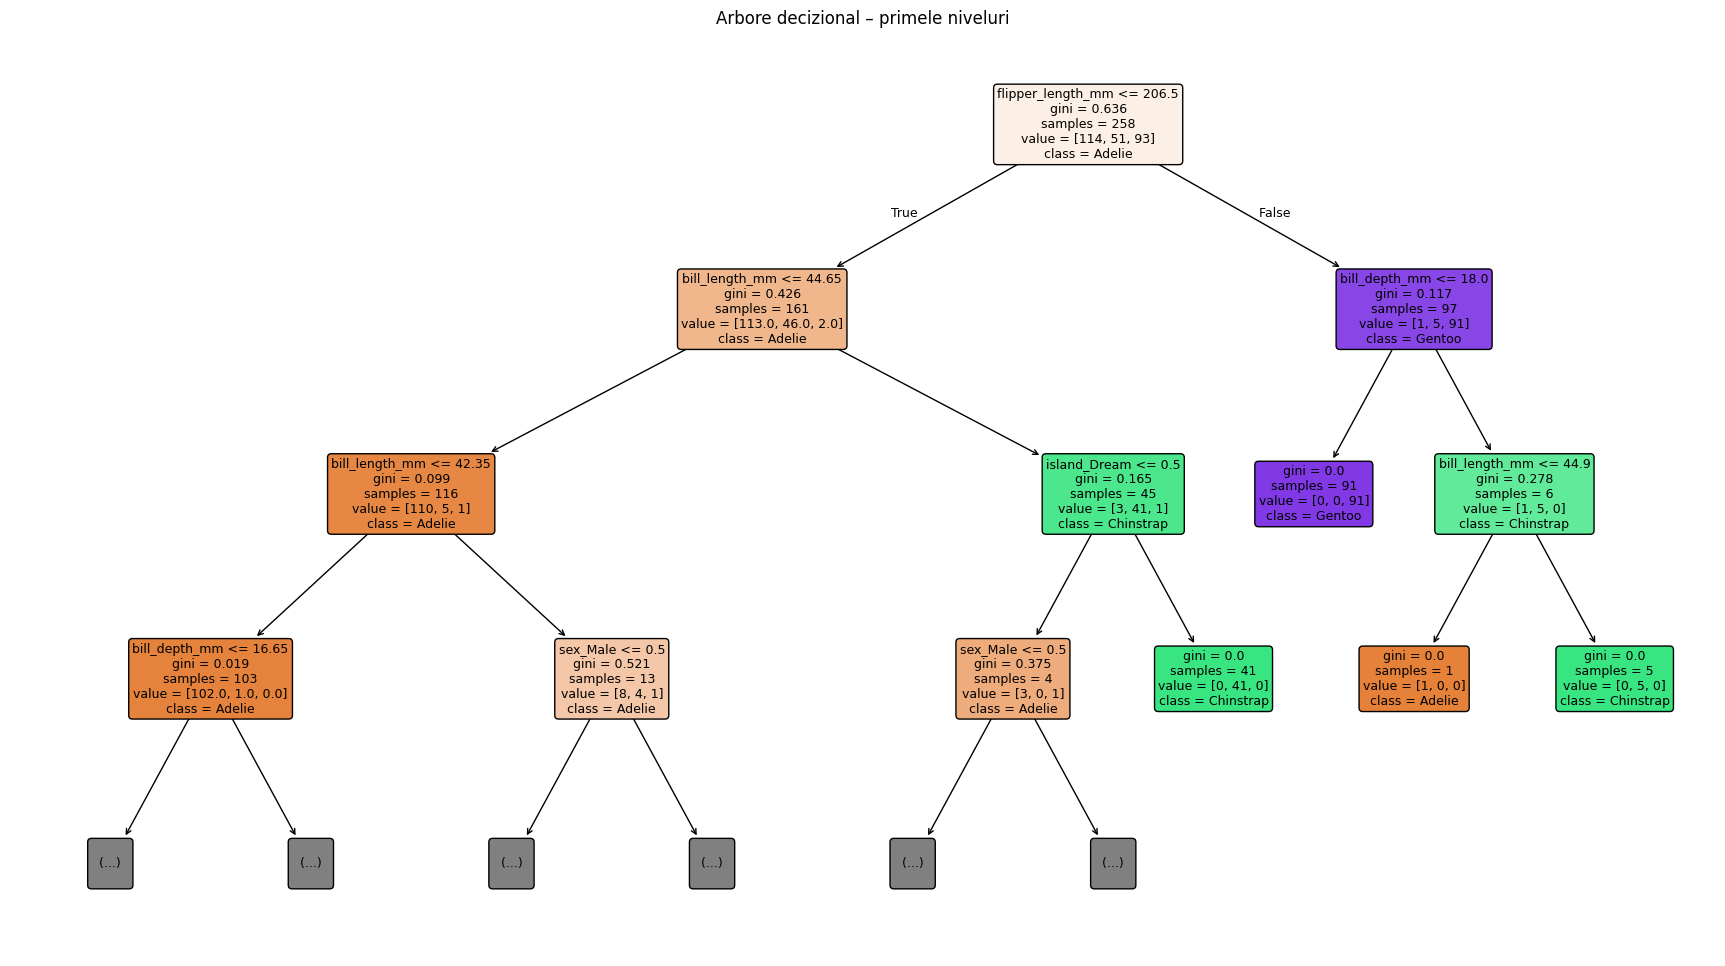

In [23]:
tree_model = model_multi
feature_names = X_train.columns

plt.figure(figsize=(22, 12))
plot_tree(
    tree_model,
    feature_names=list(feature_names),
    class_names=encoder.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title("Arbore decizional – primele niveluri")
plt.show()

### 6.4. Regulile de clasificare

Regulile învățate de arbore pot fi afișate sub formă de text cu `export_text()`. Aceste reguli permit interpretarea traseului parcurs de o observație și identificarea condițiilor care conduc la o anumită clasă.

In [24]:
rules = export_text(
    tree_model,
    feature_names=list(feature_names),
    max_depth=4
)
print(rules)

|--- flipper_length_mm <= 206.50
|   |--- bill_length_mm <= 44.65
|   |   |--- bill_length_mm <= 42.35
|   |   |   |--- bill_depth_mm <= 16.65
|   |   |   |   |--- bill_length_mm <= 39.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- bill_length_mm >  39.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- bill_depth_mm >  16.65
|   |   |   |   |--- class: 0
|   |   |--- bill_length_mm >  42.35
|   |   |   |--- sex_Male <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- sex_Male >  0.50
|   |   |   |   |--- bill_depth_mm <= 17.38
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- bill_depth_mm >  17.38
|   |   |   |   |   |--- class: 0
|   |--- bill_length_mm >  44.65
|   |   |--- island_Dream <= 0.50
|   |   |   |--- sex_Male <= 0.50
|   |   |   |   |--- class: 2
|   |   |   |--- sex_Male >  0.50
|   |   |   |   |--- class: 0
|   |   |--- island_Dream >  0.50
|   |   |   |--- class: 1
|--- flipper_length_mm >  206.50
|   |--- bill_depth_mm <= 18.00

### 6.5. Importanța caracteristicilor

Un arbore decizional estimează importanța caracteristicilor în funcție de contribuția acestora la reducerea impurității în nodurile în care sunt utilizate.

flipper_length_mm    0.512980
bill_length_mm       0.339991
bill_depth_mm        0.065250
sex_Male             0.039576
island_Dream         0.036106
island_Biscoe        0.006097
body_mass_g          0.000000
island_Torgersen     0.000000
sex_Female           0.000000
dtype: float64


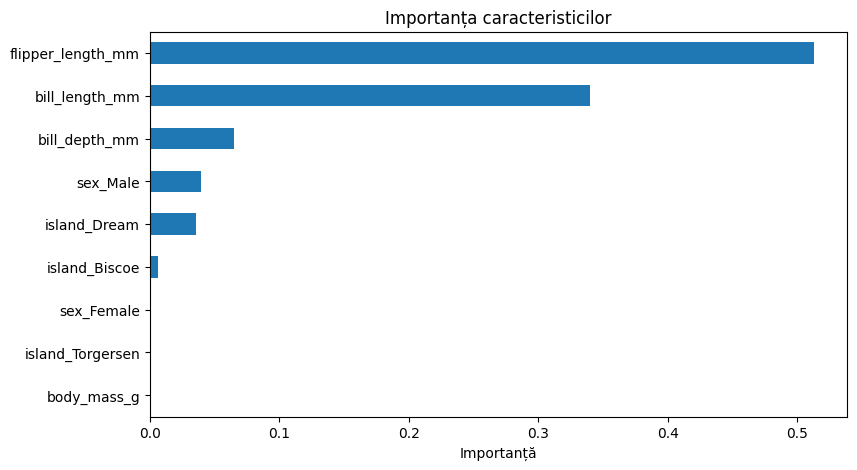

In [25]:
feature_importance = pd.Series(
    tree_model.feature_importances_,
    index=list(feature_names)
).sort_values(ascending=False)

print(feature_importance)

feature_importance.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Importanța caracteristicilor"
)
plt.xlabel("Importanță")
plt.show()

## 7. Optimizarea hiperparametrilor cu `GridSearchCV`

Pentru identificarea unei configurații potrivite se poate utiliza `GridSearchCV`. Acesta testează sistematic combinații de hiperparametri și estimează performanța fiecărei combinații prin validare încrucișată.

În exemplu sunt comparate criteriile `gini` și `entropy`, mai multe valori pentru `max_depth`, `min_samples_split` și `min_samples_leaf`. Optimizarea se realizează pe setul de antrenare al problemei multiclasă.

In [26]:
params_tree = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 3, 5, 7],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_tree = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=params_tree,
    scoring="accuracy",
    cv=5,
    n_jobs=-1
)

grid_tree.fit(X_train, y_train)

print("Cei mai buni parametri:", grid_tree.best_params_)
print("Cea mai bună acuratețe medie CV:", grid_tree.best_score_)

Cei mai buni parametri: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 10}
Cea mai bună acuratețe medie CV: 0.9689291101055808


### Evaluarea celui mai bun model

In [27]:
best_tree = grid_tree.best_estimator_
y_pred_best = best_tree.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_best)
precision = precision_score(y_test, y_pred_best, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred_best, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred_best, average="macro", zero_division=0)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.9883720930232558
Precision: 0.9814814814814815
Recall: 0.9912280701754387
F1-score: 0.9860317460317459
